# Imports and load data

## Import libraries

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cmcrameri import cm
import os
import socket
from roaring_landmask import RoaringLandmask
from scipy.stats import t
# ------------------------------------------------------------
# Load mean IWC profile data
# ------------------------------------------------------------


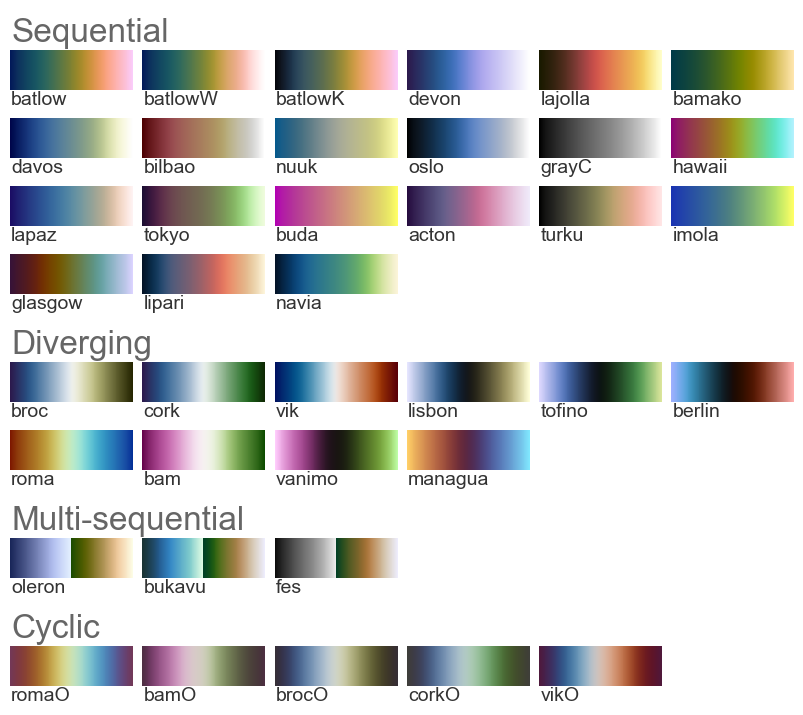

In [36]:
cm.show_cmaps()

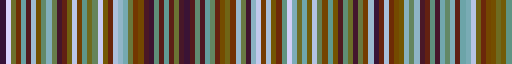

In [37]:
cm.glasgowS

In [38]:
# Helper
def describe(arr):
    return {
        "count": arr.size,
        "mean": np.mean(arr),
        "std": np.std(arr),
        "min": np.min(arr),
        "5%": np.percentile(arr, 5),
        "25%": np.percentile(arr, 25),
        "50%": np.percentile(arr, 50),
        "75%": np.percentile(arr, 75),
        "95%": np.percentile(arr, 95),
        "max": np.max(arr),
    }


## Load data (Only bulk_data_df important)

In [39]:
# if socket.gethostname()=='iacmac-ds4990':
#     BULK_PATH = "/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/02"
# else:
#     BULK_PATH = "/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics"
# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# iwc_rel_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2007.parquet"))
# iwc_rel_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2008.parquet"))
# mean_iwc_by_height_df = pd.read_parquet(os.path.join(BULK_PATH,"mean_iwc_by_height_data_V3_1_2007.parquet"))
# iwc_rel_df_loaded = pd.concat([iwc_rel_df_1, iwc_rel_df_2], ignore_index=True)

# bulk_data_df_list=[]
# for year in range(2006,2011):
#     # if year == 2010:
#     #     continue
#     bulk_data_df_list.append(pd.read_parquet(os.path.join(BULK_PATH,f"glaciations_with_bulk_data_V3_1_{year}.parquet")))

bulk_data_df = pd.read_parquet("/wolke_scratch/dnikolo/ICON_Data/sedim_search/R2B4/wbf_v3/postprocessing_output/Final_results/2007_glac_04_bulk.parquet")
bulk_data_df = bulk_data_df[~bulk_data_df["is_large_pix_cloud"]]
bulk_data_df = bulk_data_df[bulk_data_df["avg_lat"]>30]
# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# bulk_data_debug = pd.read_parquet(os.path.join("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/glaciations_with_bulk_data_V3_1_2007.parquet"))


Filter rows with no measurements (Cehck why are there such???)

In [40]:
test_cloud = bulk_data_df.iloc[5]
test_cloud.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'size_hist_km_debug', 'model_grid_ncell', 'min_temp', 'max_temp',
       'pole', 'Hemisphere', 'Lifetime [h]', 'Radius [km]', 'Level',
       'Optical T

In [41]:
test_cloud.bulk_values

array([array([-4.3037586 , -4.1492724 , -3.9947863 , -3.5403724 , -1.3848697 ,
               0.9188874 ,  2.6199753 ,  2.6577885 ,  2.14052   ,  1.7548442 ,
               1.4236995 ,  1.0952818 ,  0.76828194,  0.40369725, -1.940507  ,
              -2.3466668 , -3.059187  , -4.301305  ,         nan,         nan,
                      nan,         nan,         nan,         nan,         nan],
             dtype=float32)                                                    ,
       array([-3.7586098 , -3.7380497 , -3.7174897 , -3.097074  ,  0.27933097,
               3.655736  ,  5.8268027 ,  5.1867204 ,  4.5466385 ,  4.1697416 ,
               3.8350925 ,  3.402675  ,  2.9730928 ,  2.4946654 ,         nan,
                      nan,         nan,         nan,         nan,         nan,
                      nan,         nan,         nan,         nan,         nan],
             dtype=float32)                                                    ,
       array([-3.7586098 , -3.7380497 , -3.717

## Split cells by pass

In [42]:
columns = [
    "Cloud_ID", "Time [m]", "Magnitude", "Glac_start_ind", "Glac_peak_ind",
    "tracknumber", "is_large_pix_cloud", "avg_size[km]", "avg_ctp",
    "avg_ctt", "pole", "Hemisphere", "Lifetime [h]", "bulk_values","track_length","track_start_time"
]

bulk_data_df_split = (
    bulk_data_df[columns]
    .assign(
        timestep=lambda x: x["bulk_values"].map(
            lambda values: np.arange(len(values))
        )
    )
    .explode(["bulk_values", "timestep"], ignore_index=True)
)



In [43]:
bulk_data_df_split["timestep"] = bulk_data_df_split["timestep"].astype("int64")

In [44]:
bulk_data_df_split["rel_ind"] = bulk_data_df_split.timestep - bulk_data_df_split.Glac_peak_ind 

In [45]:
bulk_data_df_split["rel_time_min"] = bulk_data_df_split["rel_ind"]*15


In [46]:
((bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & (bulk_data_df_split["avg_ctt"]-273.15)>-36)).value_counts()

avg_ctt
True    2198904
Name: count, dtype: int64

In [47]:
sample = bulk_data_df_split.sample(1000, random_state=1)

# Settings

In [48]:
# Working version. IMPORTANT. DON'T DELETE!!!
# l2_start = 4
# l_depth=8
# n_agg_levels=3

l2_start = 4
l_depth=7
n_agg_levels=4

n_total_levels = l2_start+l_depth*(n_agg_levels-1)
if n_total_levels>25:
    raise ValueError(f"No more than 30 total levels now {n_total_levels}")
iqr_filter_y=True
iqr_filter_x=True
ind_range = [-3, 4]
rel_times_min = np.array(np.arange(ind_range[0],ind_range[1])*15,dtype=int)
timesteps = [i for i in range(2, -3, -1)]
mean_mode = "log"
confidence_level = 0.90  # 0.68, 0.90, 0.95, 0.99, etc.
n_bootstrap = 5000
ALLOWED_CTH_DEV=1000
eps=1e-5

# Prepare data

## Optical properties

In [49]:
bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: ~(np.isnan(row.bulk_values[:l2_start+l_depth*2]).any()), axis=1)

In [50]:
bulk_data_df_split["continious_cloud"].value_counts()

continious_cloud
True     1549433
False     649471
Name: count, dtype: int64

## Filter Data

In [51]:
landmask = RoaringLandmask.new()
def classify_surface(lats, lons):
    """
    lats, lons: arrays in degrees
    returns: array of 'maritime' or 'land'
    """
    is_land = np.array([
        landmask.contains(lon, lat)
        for lat, lon in zip(lats, lons)
    ])

    return np.where(is_land, "land", "maritime")


# bulk_data_df_split["surface_type"] = bulk_data_df_split.apply(lambda row: classify_surface(
#     row["lat_hist"],
#     row["lon_hist"]
# ),axis=1)
# bulk_data_df_split["is_maritime"] = bulk_data_df_split.apply(lambda row: (row["surface_type"]=="maritime").mean()>=1, axis=1)

In [52]:
(bulk_data_df_split.track_length / pd.Timedelta(minutes=15) > bulk_data_df_split["Glac_peak_ind"]).value_counts()

True     1813229
False     385675
Name: count, dtype: int64

In [53]:
# Filter only for clouds that survive after glaciation
# bulk_data_colocated = bulk_data_df_split[bulk_data_df_split["val_seviri_coincidence"]]
bulk_data_filtered = bulk_data_df_split[bulk_data_df_split.track_length / pd.Timedelta(minutes=15) > bulk_data_df_split["Glac_peak_ind"]]
# Filter for cloud lifetime - not too long
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.track_length < pd.Timedelta(hours=12)]

# Filter for significant bulk optical thickness
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["3km_cot"]>0.3]
# Select only one pass where 2 are available
# bulk_data_filtered = bulk_data_filtered.drop_duplicates(subset="Cloud_ID", keep="first")
# Filter for cclouds where extinction doesn't drop in the 2 kilometers
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["continious_cloud"]]
#Smaller than 90th percentile of DARDAR-CLAAS colocated clouds
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["avg_size[km]"]<52467.89809747548]
#Higher and lowere than 90th and 10th percentile of DARDAR-CLAAS colocated clouds
((bulk_data_filtered["avg_ctp"]>448*1e2) & (bulk_data_filtered["avg_ctp"]<673.2685720938223*1e2)).value_counts()
# Filter for cloud type
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Altostratus", "Nimbostratus", "Stratocumulus", "Stratus"])]
# bulk_data_filtered= bulk_data_filtered[~bulk_data_filtered["Cloud type"].isin(["Deep convection", "Cirrus", "Cirrostratus"])]
# Remove clouds outside measurement boundaries
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 < 0]
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 > -36]
# Take only maritime clouds
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["is_maritime"]]
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Hemisphere"]=="South"]
# stats_by_rel_time = generate_stats_by_rel_time(bulk_data_filtered, mode="mean")
bulk_data_filtered

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,tracknumber,is_large_pix_cloud,avg_size[km],avg_ctp,avg_ctt,pole,Hemisphere,Lifetime [h],bulk_values,track_length,track_start_time,timestep,rel_ind,rel_time_min,continious_cloud
30,87,15,0.496691,2,3,88.0,False,35346.713867,77778.650391,270.517433,np,North,1.75,"[-8.363756, -6.572479, -4.781202, -2.9899244, ...",0 days 01:45:00,2007-01-01 05:00:00,0,-3,-45,True
31,87,15,0.496691,2,3,88.0,False,35346.713867,77778.650391,270.517433,np,North,1.75,"[-8.363756, -6.572479, -4.781202, -2.9899244, ...",0 days 01:45:00,2007-01-01 05:00:00,1,-2,-30,True
32,87,15,0.496691,2,3,88.0,False,35346.713867,77778.650391,270.517433,np,North,1.75,"[-8.363756, -6.572479, -4.781202, -2.9899244, ...",0 days 01:45:00,2007-01-01 05:00:00,2,-1,-15,True
33,87,15,0.496691,2,3,88.0,False,35346.713867,77778.650391,270.517433,np,North,1.75,"[-8.363756, -6.572479, -11.508984, -0.64090586...",0 days 01:45:00,2007-01-01 05:00:00,3,0,0,True
34,87,15,0.496691,2,3,88.0,False,35346.713867,77778.650391,270.517433,np,North,1.75,"[-10.083052, -9.416475, -8.749899, -8.083323, ...",0 days 01:45:00,2007-01-01 05:00:00,4,1,15,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2198887,1882343,15,0.437503,13,14,4773.0,False,48774.371608,50505.619655,240.114754,np,North,4.50,"[-11.826942, -11.435298, -11.043653, -18.69701...",0 days 04:30:00,2007-12-14 19:30:00,13,-1,-15,True
2198888,1882343,15,0.437503,13,14,4773.0,False,48774.371608,50505.619655,240.114754,np,North,4.50,"[-11.826942, -11.435298, -11.043653, -10.65200...",0 days 04:30:00,2007-12-14 19:30:00,14,0,0,True
2198889,1882343,15,0.437503,13,14,4773.0,False,48774.371608,50505.619655,240.114754,np,North,4.50,"[-11.826942, -11.435298, -11.043653, -10.65200...",0 days 04:30:00,2007-12-14 19:30:00,15,1,15,True
2198890,1882343,15,0.437503,13,14,4773.0,False,48774.371608,50505.619655,240.114754,np,North,4.50,"[-19.199554, -19.669905, -20.140255, -10.65200...",0 days 04:30:00,2007-12-14 19:30:00,16,2,30,True


## Z_Meas

In [54]:
def extract_bulk_samples_by_time(df):
    Z_meas = {}
    t_meas = {}
    ext_meas = {}
    iwc_meas = {}
    for rel_ind in np.arange(-5,5):
        Z_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["bulk_values"].to_numpy())
        # t_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["temp_bulk_means"].to_numpy())
        # iwc_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["iwc_bulk_means"].to_numpy())
        # ext_meas[rel_ind]=df[df["rel_ind"]==rel_ind]["ct_depth"].to_numpy()
    return Z_meas#, t_meas, ext_meas, iwc_meas

Z_meas = extract_bulk_samples_by_time(bulk_data_filtered) #, t_meas, ext_meas, iwc_meas


# Correlation data

In [55]:
corr_peak_ci = pd.read_parquet("/wolke_scratch/dnikolo/MSGI/plotting/Publication_figures/IF_autocorrelation_values_model.parquet")

# Statistics

## Settings

In [56]:
# ------------------------------------------------------------------
# 0. Configuration
# ------------------------------------------------------------------
PEAK_IND = 0
# Absolute index (same numbering as `inds`) of the column where
# rel_ind == 0. Must be set. E.g. PEAK_IND = ind_range[0] + 8

WEIGHT_MODE = "none"
# "residual" : w = 1 - rho**2   -> variance not shared with the peak
# "abs"      : w = 1 - |rho|
# "signed"   : w = 1 - max(rho, 0)   (ignores anticorrelation)
# "none"     : w = 1                 (reproduces your current result)

WEIGHT_FLOOR = 0.00
# Minimum weight. rho == 1 at the peak would otherwise delete that
# column from every reference sample. Set to 0.0 to allow that.

INVERT_WEIGHTS = False
# True -> emphasise peak-correlated times instead of down-weighting
# them (w = rho**2 etc.). Use if you want the reference to be "the
# same storms", not "independent background".

EQUALISE_INDEX_SIZE = False
# True -> additionally divide by the per-index cloud count, so each
# time index contributes equally regardless of how many clouds it has
# (n_clouds in your table ranges 46k-348k).

## Calculate

In [57]:

inds = np.arange(ind_range[0], ind_range[1])

# Original vertical levels
y_levels = np.arange(0,3000,120)

# New grouped levels using old level indices

level_groups = [
    list(range(0, l2_start)), 
]
level_groups.extend([list(range(l2_start+i*l_depth, l2_start+(i+1)*l_depth)) for i in range(n_agg_levels-1)])

n_levels = len(level_groups)
n_times = len(inds)

mean_map = np.full((n_levels, n_times), np.nan)
std_map  = np.full((n_levels, n_times), np.nan)
n_map    = np.full((n_levels, n_times), np.nan)

# Adjust this if your columns correspond to different relative indices
# rel_times_min = np.array([-45, -30, -15, 0, 15, 30, 45])


# level_labels = [
#     "Cloud top",
#     " -560 to -1360 m ",
#     "-1360 to -2160 m ",
# ]

level_labels = [
    "Cloud top",
    # f" -{l2_start*120} to -{(l2_start+l_depth)*120} m ",
    # f" -{(l2_start+l_depth)*120} to -{(l2_start+2*l_depth)*120} m ",
]

level_labels.extend([f" -{(l2_start+i*l_depth)*120} to -{(l2_start+(i+1)*l_depth)*120} m " for i in range(n_agg_levels-1)])


In [58]:
# --------------------------------------------------------------
# Vertical averaging method
#
# "linear": convert dBZ -> Z, average Z, convert back to dBZ
# "log":    arithmetic mean of dBZ values
# --------------------------------------------------------------

if mean_mode not in {"linear", "log"}:
    raise ValueError(
        "mean_mode must be either 'linear' or 'log'"
    )


def calculate_layer_mean_dbz(dbz_block, mode):
    """
    Calculate one vertically averaged dBZ value per cloud.

    Parameters
    ----------
    dbz_block : ndarray
        Shape: clouds x vertical levels.
    mode : {"linear", "log"}
        "linear": average in linear reflectivity space.
        "log": average dBZ values directly.

    Returns
    -------
    ndarray
        One layer-averaged dBZ value per cloud.
    """
    dbz_block = np.asarray(dbz_block, dtype=float)

    valid_counts = np.sum(
        np.isfinite(dbz_block),
        axis=1,
    )

    if mode == "linear":
        linear_z = 10.0 ** (dbz_block / 10.0)

        mean_linear_z = np.divide(
            np.nansum(linear_z, axis=1),
            valid_counts,
            out=np.full(dbz_block.shape[0], np.nan),
            where=valid_counts > 0,
        )

        cloud_values = 10.0 * np.log10(mean_linear_z)

    else:  # mode == "log"
        cloud_values = np.divide(
            np.nansum(dbz_block, axis=1),
            valid_counts,
            out=np.full(dbz_block.shape[0], np.nan),
            where=valid_counts > 0,
        )
    

    return cloud_values


dbZ_grouped_by_ind = {}
cloud_group_values_by_ind = {}

for col, ind in enumerate(inds):
    dbZ = np.asarray(
        Z_meas[ind],
        dtype=float,
    ).copy()

    dbZ[~np.isfinite(dbZ)] = np.nan

    # Shape: clouds x grouped vertical levels
    cloud_group_matrix = np.full(
        (dbZ.shape[0], n_levels),
        np.nan,
    )

    grouped_dbZ = []

    for i, group in enumerate(level_groups):
        cloud_values = calculate_layer_mean_dbz(
            dbZ[:, group],
            mode=mean_mode,
        )

        # Preserve row alignment for cloud-level bootstrapping
        cloud_group_matrix[:, i] = cloud_values

        # Finite sample used for statistics
        finite_values = cloud_values[
            np.isfinite(cloud_values)
        ]

        grouped_dbZ.append(finite_values)

        if len(finite_values) >= 1:
            mean_map[i, col] = np.mean(finite_values)
            n_map[i, col] = len(finite_values)

        if len(finite_values) >= 2:
            std_map[i, col] = np.std(
                finite_values,
                ddof=1,
            )

    dbZ_grouped_by_ind[ind] = grouped_dbZ
    cloud_group_values_by_ind[ind] = cloud_group_matrix

sem_map = std_map / np.sqrt(n_map)

In [59]:
"""
Correlation-weighted pooled deviations.

Drop-in replacement for the Welch-test loop and the bootstrap block.
Assumes the following already exist from your current code:

    inds, n_levels, n_times, mean_map, std_map, n_map,
    dbZ_grouped_by_ind, cloud_group_values_by_ind,
    iqr_filter_x, iqr_filter_y, n_bootstrap, confidence_level,
    corr_peak_ci  (DataFrame with rel_ind, corr_with_peak)
"""





# ------------------------------------------------------------------
# 1. Build one scalar weight per time index
# ------------------------------------------------------------------
def build_index_weights(
    corr_table,
    inds,
    peak_ind,
    mode=WEIGHT_MODE,
    floor=WEIGHT_FLOOR,
    invert=INVERT_WEIGHTS,
):
    """Map each absolute index in `inds` to a weight derived from rho."""

    if peak_ind is None:
        raise ValueError("PEAK_IND must be set (absolute index of rel_ind == 0)")

    rho_lookup = dict(
        zip(
            corr_table["rel_ind"].astype(int),
            corr_table["corr_with_peak"].astype(float),
        )
    )

    weights = {}

    for ind in inds:
        rel = int(ind) - int(peak_ind)
        rho = rho_lookup.get(rel, np.nan)

        if not np.isfinite(rho):
            # No correlation estimate for this lag: fall back to floor
            weights[ind] = max(floor, 0.0)
            continue

        rho = float(np.clip(rho, -1.0, 1.0))

        if mode == "residual":
            redundancy = rho ** 2
        elif mode == "abs":
            redundancy = abs(rho)
        elif mode == "signed":
            redundancy = max(rho, 0.0)
        elif mode == "none":
            redundancy = 0.0
        else:
            raise ValueError(f"unknown WEIGHT_MODE: {mode}")

        w = redundancy if invert else 1.0 - redundancy
        weights[ind] = max(float(w), floor)

    if EQUALISE_INDEX_SIZE:
        for ind in inds:
            n_clouds = cloud_group_values_by_ind[ind].shape[0]
            if n_clouds > 0:
                weights[ind] /= n_clouds

    # Rescale to mean 1. Purely cosmetic: weighted means and n_eff are
    # both scale invariant, so this changes nothing numerically.
    scale = np.mean(list(weights.values()))
    if scale > 0:
        weights = {k: v / scale for k, v in weights.items()}

    return weights


index_weights = build_index_weights(corr_peak_ci, inds, PEAK_IND)


# ------------------------------------------------------------------
# 2. Weighted moments
# ------------------------------------------------------------------
def weighted_moments(values, weights):
    """
    Weighted mean, unbiased weighted variance, and Kish effective n.

    Uses reliability weights, so the variance denominator reduces to
    (n - 1) when all weights are equal. The variance of the weighted
    mean is then simply var / n_eff.
    """
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)

    ok = np.isfinite(v) & np.isfinite(w) & (w > 0)
    v, w = v[ok], w[ok]

    if v.size == 0:
        return np.nan, np.nan, 0.0

    sw = w.sum()
    mean = np.sum(w * v) / sw
    n_eff = sw ** 2 / np.sum(w ** 2)

    if v.size < 2 or n_eff <= 1:
        return mean, np.nan, n_eff

    denom = sw - np.sum(w ** 2) / sw
    var = np.sum(w * (v - mean) ** 2) / denom

    return mean, var, n_eff


def iqr_mask(x, k=1.5):
    """Boolean keep-mask, so weights stay aligned with values."""
    x = np.asarray(x, dtype=float)
    finite = np.isfinite(x)

    if finite.sum() < 4:
        return finite

    q1, q3 = np.nanpercentile(x[finite], [25, 75])
    iqr = q3 - q1

    if iqr == 0 or not np.isfinite(iqr):
        return finite

    return finite & (x >= q1 - k * iqr) & (x <= q3 + k * iqr)


# ------------------------------------------------------------------
# 3. Welch loop against a correlation-weighted reference
# ------------------------------------------------------------------
p_welch_map = np.full_like(mean_map, np.nan)
dev_vs_others_map = np.full_like(mean_map, np.nan)
effect_size_map = np.full_like(mean_map, np.nan)

n_x_map = np.full_like(mean_map, np.nan)
n_y_raw_map = np.full_like(mean_map, np.nan)
n_y_clean_map = np.full_like(mean_map, np.nan)
n_y_eff_map = np.full_like(mean_map, np.nan)

for j, ind in enumerate(inds):
    x_groups = dbZ_grouped_by_ind[ind]
    other_inds = [k for k in inds if k != ind]

    for i in range(n_levels):
        x = x_groups[i]
        x = x[np.isfinite(x)]

        # Pool the same grouped level from all other time indices,
        # carrying each index's weight alongside its values.
        y_parts, w_parts = [], []
        for k in other_inds:
            vals = dbZ_grouped_by_ind[k][i]
            vals = vals[np.isfinite(vals)]
            if vals.size == 0:
                continue
            y_parts.append(vals)
            w_parts.append(np.full(vals.size, index_weights[k]))

        if not y_parts:
            continue

        y = np.concatenate(y_parts)
        wy = np.concatenate(w_parts)

        n_y_raw = y.size

        if iqr_filter_y:
            keep = iqr_mask(y, k=1.5)
            y, wy = y[keep], wy[keep]
        if iqr_filter_x:
            keep = iqr_mask(x, k=1.5)
            x = x[keep]

        if x.size < 2 or y.size < 2:
            continue

        # x carries a single weight, so weighted == unweighted here.
        mx = np.mean(x)
        vx = np.var(x, ddof=1)
        nx = x.size

        my, vy, ny_eff = weighted_moments(y, wy)

        if not np.isfinite(vy) or ny_eff <= 1:
            continue

        dev = mx - my
        se = np.sqrt(vx / nx + vy / ny_eff)

        if se == 0 or not np.isfinite(se):
            continue

        tval = dev / se

        df_num = (vx / nx + vy / ny_eff) ** 2
        df_den = (
            ((vx / nx) ** 2) / (nx - 1)
            + ((vy / ny_eff) ** 2) / (ny_eff - 1)
        )

        if df_den == 0 or not np.isfinite(df_den):
            continue

        df = df_num / df_den
        p = 2 * t.sf(np.abs(tval), df)

        pooled_sd = np.sqrt((vx + vy) / 2)

        p_welch_map[i, j] = p
        dev_vs_others_map[i, j] = dev

        if pooled_sd > 0 and np.isfinite(pooled_sd):
            effect_size_map[i, j] = dev / pooled_sd

        n_x_map[i, j] = nx
        n_y_raw_map[i, j] = n_y_raw
        n_y_clean_map[i, j] = y.size
        n_y_eff_map[i, j] = ny_eff

sem_map = std_map / np.sqrt(n_map)


# ------------------------------------------------------------------
# 4. Bootstrap with the same weighting
# ------------------------------------------------------------------
def calculate_pooled_deviations(cloud_arrays, inds, n_levels, weights):
    """Deviation of each time mean from the weighted pool of all others."""

    n_times = len(inds)
    deviations = np.full((n_levels, n_times), np.nan)

    for j, ind in enumerate(inds):
        other_inds = [k for k in inds if k != ind]

        for i in range(n_levels):
            x = cloud_arrays[ind][:, i]
            x = x[np.isfinite(x)]

            y_parts, w_parts = [], []
            for k in other_inds:
                vals = cloud_arrays[k][:, i]
                vals = vals[np.isfinite(vals)]
                if vals.size == 0:
                    continue
                y_parts.append(vals)
                w_parts.append(np.full(vals.size, weights[k]))

            if x.size == 0 or not y_parts:
                continue

            y = np.concatenate(y_parts)
            wy = np.concatenate(w_parts)

            deviations[i, j] = np.mean(x) - np.sum(wy * y) / wy.sum()

    return deviations


rng = np.random.default_rng(42)

index_bootstrap = np.full((n_bootstrap, n_times - 1), np.nan)

for b in range(n_bootstrap):
    bootstrap_arrays = {}

    for ind in inds:
        values = cloud_group_values_by_ind[ind]
        n_clouds = values.shape[0]

        # Resample complete cloud rows
        sample_indices = rng.integers(0, n_clouds, size=n_clouds)
        bootstrap_arrays[ind] = values[sample_indices]

    bootstrap_deviations = calculate_pooled_deviations(
        bootstrap_arrays,
        inds,
        n_levels,
        index_weights,
    )

    index_bootstrap[b] = (
        bootstrap_deviations[1, :-1] + bootstrap_deviations[2, 1:]
    )

if not 0 < confidence_level < 1:
    raise ValueError("confidence_level must be between 0 and 1")

alpha = 1.0 - confidence_level
lower_percentile = 100.0 * alpha / 2.0
upper_percentile = 100.0 * (1.0 - alpha / 2.0)

sedimentation_index = (
    dev_vs_others_map[1, :-1] + dev_vs_others_map[2, 1:]
)

(
    sedimentation_index_ci_low,
    sedimentation_index_ci_high,
) = np.nanpercentile(
    index_bootstrap,
    [lower_percentile, upper_percentile],
    axis=0,
)


# ------------------------------------------------------------------
# 5. Sanity check: how much did the weighting move things?
# ------------------------------------------------------------------
if __name__ == "__main__":
    for ind in inds:
        rel = int(ind) - int(PEAK_IND)
        print(f"ind {ind:>4}  rel {rel:>3}  w = {index_weights[ind]:.3f}")

    print("\neffective vs raw n for the pooled reference:")
    print(np.round(n_y_eff_map / n_y_clean_map, 3))

ind   -3  rel  -3  w = 1.000
ind   -2  rel  -2  w = 1.000
ind   -1  rel  -1  w = 1.000
ind    0  rel   0  w = 1.000
ind    1  rel   1  w = 1.000
ind    2  rel   2  w = 1.000
ind    3  rel   3  w = 1.000

effective vs raw n for the pooled reference:
[[1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]]


# Bulk Plot

## Set style

In [60]:
import matplotlib.gridspec as gridspec
import cmcrameri
import matplotlib.font_manager as fm
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm

In [61]:

# %matplotlib inline
# plt.rc('font',family='arial')
# plt.rcParams.update({"font.size":6})
# font= fm.FontProperties(family='arial')
# mpl.rcParams['pdf.fonttype'] = 42
# mpl.rcParams['ps.fonttype'] = 42
# # cmcrameri.cm.show_cmaps()
arial_path = "/wolke_scratch/dnikolo/MSGI/plotting/Publication_figures/arial/ARIAL.TTF"

fm.fontManager.addfont(arial_path)
font_name = fm.FontProperties(fname=arial_path).get_name()

mpl.rcParams.update({
    "font.family": font_name,
    "font.size": 6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})



In [62]:
classifiacation_palette = cmcrameri.cm.actonS.colors[[i for i in range(10) if i != 1],:]

## Bulk publication figure

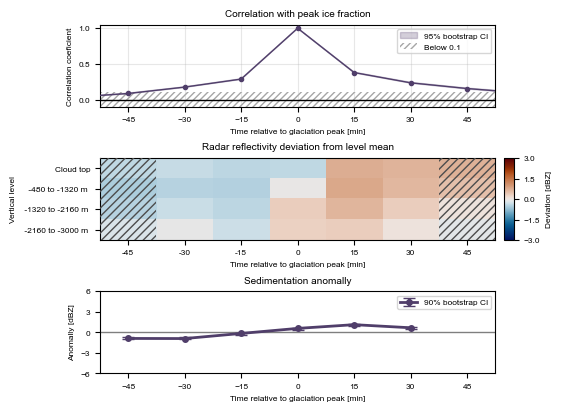

In [63]:

# fig = plt.figure(figsize=(6.69291, 6.69291*3.504/5.501), constrained_layout=True) 170 mm
fig = plt.figure(figsize=(5.501, 4), constrained_layout=True)#5.501*3.504/5.501), constrained_layout=True)
gs = gridspec.GridSpec(3, 3,height_ratios=[1, 1,1], width_ratios=[1,1,0.05],figure=fig)#,hspace=1.2, wspace=0.3)#,
ax_heat = fig.add_subplot(gs[1, :2])
ax_top_cb = fig.add_subplot(gs[1, 2])
ax_anom = fig.add_subplot(gs[2, :2])
ax_corr = fig.add_subplot(gs[0, :2])


# Common axes formatting
for ax in (ax_heat,):
    ax.set_xticks(np.arange(len(rel_times_min)))
    ax.set_xticklabels(rel_times_min)
    ax.set_yticks(np.arange(len(level_labels)))
    ax.set_yticklabels(level_labels)
    ax.set_ylabel("Vertical level")
    ax.set_xlabel("Time relative to glaciation peak [min]")

vmax = np.nanmax(np.abs(dev_vs_others_map))



ax_heat.set_title("Radar reflectivity deviation from level mean")

im1 = ax_heat.imshow(
    dev_vs_others_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3),
    origin="upper",
)

cbar = fig.colorbar(im1, cax=ax_top_cb)
cbar.set_label("Deviation [dBZ]")  # Adjust units/label as needed
cbar.set_ticks([-3, -1.5, 0, 1.5, 3])
index_times = rel_times_min[:-1]

ci_percent = 100 * confidence_level
# ax_anom
ax_anom.errorbar(
    index_times,
    sedimentation_index,
    yerr=np.vstack([
        np.maximum(
            sedimentation_index - sedimentation_index_ci_low,
            0,
        ),
        np.maximum(
            sedimentation_index_ci_high - sedimentation_index,
            0,
        ),
    ]),
    marker="o",
    linewidth=2,
    markersize=4,
    capsize=4,
    label=f"{ci_percent:g}% bootstrap CI",
    color=classifiacation_palette[4]
)

ax_anom.legend()
ax_anom.axhline(
    0,
    color="k",
    linewidth=1,
    alpha=0.5,
)

ax_anom.set_xticks(rel_times_min)
ax_anom.set_xlabel("Time relative to glaciation peak [min]")
ax_anom.set_ylabel("Anomally [dBZ]")
ax_anom.set_title("Sedimentation anomally")
ax_anom.set_xlim(-45-7.5,+45+7.5)
ax_anom.legend(loc="upper right")
ax_anom.set_ylim(-6,6)
ax_anom.set_yticks(np.arange(-6,7,3))

ax_corr.plot(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["corr_with_peak"],
    marker="o",
    markersize=3,
    linewidth=1,
    # label="Correlation with peak",
    zorder=3,
    color=classifiacation_palette[4]
)

ax_corr.fill_between(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["ci_low"],
    corr_peak_ci["ci_high"],
    alpha=0.25,
    label="95% bootstrap CI",
    zorder=2,
    color=classifiacation_palette[4]
)

# ax_corr.axvline(
#     0,
#     color="k",
#     linestyle="--",
#     linewidth=1,
#     label="Glaciation peak",
#     zorder=4,
# )

ax_corr.axhline(
    0,
    color="k",
    linewidth=1,
    zorder=4,
)

# Hatched region: correlation below 0.1
ax_corr.axhspan(
    -0.1,
    0.1,
    facecolor="none",
    edgecolor="0.65",
    hatch="/////",
    linewidth=0,
    zorder=0,
    label="Below 0.1",
)


# Find index positions of -45 and +45 min in the heatmap's x-axis
rel_times_arr = np.asarray(rel_times_min)
idx_m45 = np.where(rel_times_arr == -45)[0]
idx_p45 = np.where(rel_times_arr == 45)[0]

for idx in np.concatenate([idx_m45, idx_p45]):
    ax_heat.axvspan(
        idx - 0.5, idx + 0.5,
        facecolor="none",
        edgecolor="0.3",
        hatch="////",
        linewidth=0,
        zorder=5,
    )
# Label every 15-minute sample
xmin = corr_peak_ci["rel_time_min"].min()
xmax = corr_peak_ci["rel_time_min"].max()

xticks = np.arange(
    np.floor(xmin / 15) * 15,
    np.ceil(xmax / 15) * 15 + 15,
    15,
)

ax_corr.set_xticks(xticks)
ax_corr.set_xlim(xmin, xmax)
ax_corr.set_xlim(-45-7.5,45+7.5)


ax_corr.set_xlabel("Time relative to glaciation peak [min]")
ax_corr.set_ylabel("Correlation coeficient")
ax_corr.set_title("Correlation with peak ice fraction")
ax_corr.set_ylim(-0.1, 1.05)

ax_corr.grid(alpha=0.3)
ax_corr.legend()


fig.savefig(
    "/wolke_scratch/dnikolo/MSGI/plotting/Publication_figures/Bulk_figure_model.pdf",
    format="pdf",
    dpi=300
)

In [64]:
from pathlib import Path
import numpy as np
import pandas as pd

output_dir = Path(
    "/wolke_scratch/dnikolo/MSGI/plotting/Publication_figures/data/model"
)
output_dir.mkdir(parents=True, exist_ok=True)


# 1. Heatmap data — one row per heatmap cell
heatmap_values = np.asarray(dev_vs_others_map)

if heatmap_values.shape != (len(level_labels), len(rel_times_min)):
    raise ValueError(
        "Heatmap dimensions do not match level_labels and rel_times_min: "
        f"{heatmap_values.shape} != "
        f"({len(level_labels)}, {len(rel_times_min)})"
    )

heatmap_df = (
    pd.DataFrame(
        heatmap_values,
        index=level_labels,
        columns=rel_times_min,
    )
    .rename_axis(index="vertical_level", columns="rel_time_min")
    .stack()
    .rename("reflectivity_deviation_dbz")
    .reset_index()
)

heatmap_df.to_csv(
    output_dir / "reflectivity_deviation_heatmap.csv",
    index=False,
)


# 2. Sedimentation anomaly and confidence interval
index_times = np.asarray(rel_times_min[:-1])
sedimentation_index_arr = np.asarray(sedimentation_index)
sedimentation_ci_low_arr = np.asarray(sedimentation_index_ci_low)
sedimentation_ci_high_arr = np.asarray(sedimentation_index_ci_high)

lengths = {
    len(index_times),
    len(sedimentation_index_arr),
    len(sedimentation_ci_low_arr),
    len(sedimentation_ci_high_arr),
}
if len(lengths) != 1:
    raise ValueError(
        "Sedimentation arrays and index_times must have equal lengths."
    )

anomaly_df = pd.DataFrame({
    "rel_time_min": index_times,
    "sedimentation_anomaly_dbz": sedimentation_index_arr,
    "ci_low_dbz": sedimentation_ci_low_arr,
    "ci_high_dbz": sedimentation_ci_high_arr,
})

anomaly_df.to_csv(
    output_dir / "sedimentation_anomaly.csv",
    index=False,
)


# 3. Correlation and confidence interval
correlation_df = corr_peak_ci[
    ["rel_time_min", "corr_with_peak", "ci_low", "ci_high"]
].copy()

correlation_df.to_csv(
    output_dir / "peak_ice_fraction_correlation.csv",
    index=False,
)

# 1. Mean reflectivity — one row per heatmap cell
mean_values = np.asarray(mean_map)

expected_shape = (len(level_labels), len(rel_times_min))
if mean_values.shape != expected_shape:
    raise ValueError(
        "Mean-map dimensions do not match level_labels and rel_times_min: "
        f"{mean_values.shape} != {expected_shape}"
    )

mean_reflectivity_df = (
    pd.DataFrame(
        mean_values,
        index=level_labels,
        columns=rel_times_min,
    )
    .rename_axis(index="vertical_level", columns="rel_time_min")
    .stack()
    .rename("reflectivity_dbz")
    .reset_index()
)

mean_reflectivity_df.to_csv(
    output_dir / "mean_reflectivity.csv",
    index=False,
)


In [65]:
import json
import platform
from datetime import datetime, timezone

metadata = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "settings": {
        "l2_start": int(l2_start),
        "l_depth": int(l_depth),
        "iqr_filter_y": bool(iqr_filter_y),
        "iqr_filter_x": bool(iqr_filter_x),
        "ind_range": [int(x) for x in ind_range],
        "rel_times_min": np.asarray(rel_times_min, dtype=int).tolist(),
        "timesteps": [int(x) for x in timesteps],
        "mean_mode": str(mean_mode),
        "confidence_level": float(confidence_level),
        "confidence_level_percent": float(confidence_level * 100),
        "n_bootstrap": int(n_bootstrap),
        "peak_ind": int(PEAK_IND),
        "weight_mode": str(WEIGHT_MODE),
        "weight_floor": float(WEIGHT_FLOOR),
        "invert_weights": bool(INVERT_WEIGHTS),
        "equalise_index_size": bool(EQUALISE_INDEX_SIZE),
    },
    "files": {
        "mean_reflectivity.csv": {
            "description": (
                "Radar reflectivity means."
            ),
            "columns": {
                "vertical_level": "Vertical-level label",
                "rel_time_min": (
                    "Time relative to the glaciation peak in minutes"
                ),
                "reflectivity_dbz": (
                    "Radar reflectivity in dBZ"
                ),
            },
        },
        "reflectivity_deviation_heatmap.csv": {
            "description": (
                "Radar reflectivity deviation from the vertical-level mean."
            ),
            "columns": {
                "vertical_level": "Vertical-level label",
                "rel_time_min": (
                    "Time relative to the glaciation peak in minutes"
                ),
                "reflectivity_deviation_dbz": (
                    "Radar reflectivity deviation in dBZ"
                ),
            },
        },
        "sedimentation_anomaly.csv": {
            "description": (
                "Sedimentation anomaly with bootstrap confidence interval."
            ),
            "columns": {
                "rel_time_min": (
                    "Time relative to the glaciation peak in minutes"
                ),
                "sedimentation_anomaly_dbz": (
                    "Sedimentation anomaly in dBZ"
                ),
                "ci_low_dbz": "Lower bootstrap confidence limit in dBZ",
                "ci_high_dbz": "Upper bootstrap confidence limit in dBZ",
            },
        },
        "peak_ice_fraction_correlation.csv": {
            "description": (
                "Correlation with peak ice fraction and bootstrap "
                "confidence interval."
            ),
            "columns": {
                "rel_time_min": (
                    "Time relative to the glaciation peak in minutes"
                ),
                "corr_with_peak": "Correlation coefficient",
                "ci_low": "Lower bootstrap confidence limit",
                "ci_high": "Upper bootstrap confidence limit",
            },
        },
    },
    "software": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
}

with open(output_dir / "metadata.json", "w", encoding="utf-8") as metadata_file:
    json.dump(
        metadata,
        metadata_file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False,
    )

In [66]:
np.exp(np.mean(np.log(bulk_data_filtered[bulk_data_filtered["avg_size[km]"]<52467.89809747548]["avg_size[km]"])))

36813.129033623234

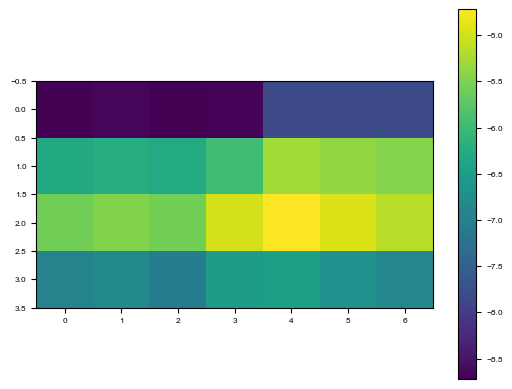

In [67]:
plt.imshow(mean_map)
plt.colorbar()

## Bias-source publication figure


In [68]:
# ------------------------------------------------------------
# Vertical deviations:
# each level versus all other levels at the same time
# ------------------------------------------------------------
dev_vs_other_levels_map = np.full_like(mean_map, np.nan)
p_welch_vertical_map = np.full_like(mean_map, np.nan)

for j, ind in enumerate(inds):
    level_samples = dbZ_grouped_by_ind[ind]

    for i in range(n_levels):
        # Reflectivity values at the current level and time
        x = np.asarray(level_samples[i], dtype=float)
        x = x[np.isfinite(x)]

        # Pool all other vertical levels at the same time
        other_levels = [
            np.asarray(level_samples[k], dtype=float)
            for k in range(n_levels)
            if k != i
        ]

        if not other_levels:
            continue

        y = np.concatenate(other_levels)
        y = y[np.isfinite(y)]

        # Consistent with your time-direction calculation:
        # remove outliers only from the reference sample
        if iqr_filter_y:
            y = pd.isna(glac_df.iloc[2].tracknumber)(y, k=1.5)
        if iqr_filter_x:
            x=remove_outliers_iqr(x,k=1.5)

        if len(x) < 2 or len(y) < 2:
            continue

        mx = np.mean(x)
        my = np.mean(y)

        vx = np.var(x, ddof=1)
        vy = np.var(y, ddof=1)

        nx = len(x)
        ny = len(y)

        dev = mx - my
        se = np.sqrt(vx / nx + vy / ny)

        dev_vs_other_levels_map[i, j] = dev

        if se <= 0 or not np.isfinite(se):
            continue

        tval = dev / se

        df_num = (vx / nx + vy / ny) ** 2
        df_den = (
            ((vx / nx) ** 2) / (nx - 1)
            + ((vy / ny) ** 2) / (ny - 1)
        )

        if df_den <= 0 or not np.isfinite(df_den):
            continue

        df = df_num / df_den
        p_welch_vertical_map[i, j] = 2 * t.sf(np.abs(tval), df)

NameError: name 'glac_df' is not defined

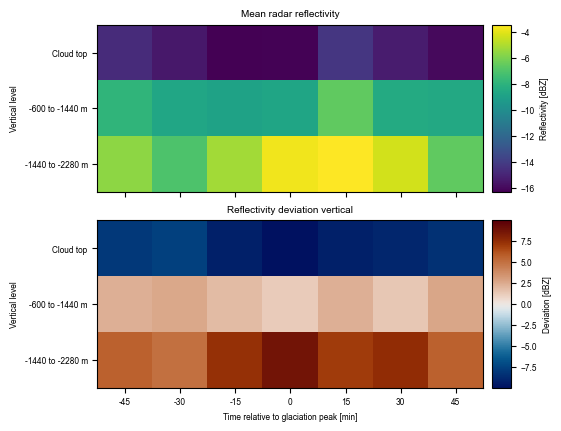

In [ ]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib import gridspec
import matplotlib.pyplot as plt
import numpy as np

fig_vertical = plt.figure(
    figsize=(5.501, 4.2),
    constrained_layout=True,
)

gs_vertical = gridspec.GridSpec(
    2,
    2,
    figure=fig_vertical,
    height_ratios=[1, 1],
    width_ratios=[1, 0.05],
)

ax_absolute = fig_vertical.add_subplot(gs_vertical[0, 0])
ax_absolute_cb = fig_vertical.add_subplot(gs_vertical[0, 1])

ax_vertical_dev = fig_vertical.add_subplot(gs_vertical[1, 0])
ax_vertical_dev_cb = fig_vertical.add_subplot(gs_vertical[1, 1])

# ------------------------------------------------------------
# Absolute reflectivity
# ------------------------------------------------------------
im_absolute = ax_absolute.imshow(
    mean_map,
    aspect="auto",
    cmap="viridis",
    origin="upper",
)

cbar_absolute = fig_vertical.colorbar(
    im_absolute,
    cax=ax_absolute_cb,
)
cbar_absolute.set_label("Reflectivity [dBZ]")

ax_absolute.set_title("Mean radar reflectivity")

# ------------------------------------------------------------
# Vertical deviations
# ------------------------------------------------------------
vertical_vmax = np.nanmax(
    np.abs(dev_vs_other_levels_map)
)

if not np.isfinite(vertical_vmax) or vertical_vmax == 0:
    vertical_vmax = 1.0

im_vertical_dev = ax_vertical_dev.imshow(
    dev_vs_other_levels_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(
        vmin=-vertical_vmax,
        vcenter=0,
        vmax=vertical_vmax,
    ),
    origin="upper",
)

cbar_vertical = fig_vertical.colorbar(
    im_vertical_dev,
    cax=ax_vertical_dev_cb,
)
cbar_vertical.set_label("Deviation [dBZ]")

ax_vertical_dev.set_title(
    "Reflectivity deviation vertical"
)

# ------------------------------------------------------------
# Common formatting
# ------------------------------------------------------------
for ax in (ax_absolute, ax_vertical_dev):
    ax.set_xticks(np.arange(len(rel_times_min)))
    ax.set_xticklabels(rel_times_min)

    ax.set_yticks(np.arange(len(level_labels)))
    ax.set_yticklabels(level_labels)

    ax.set_ylabel("Vertical level")

# Avoid repeating x-axis labels on the upper panel
ax_absolute.tick_params(
    axis="x",
    labelbottom=False,
)

ax_vertical_dev.set_xlabel(
    "Time relative to glaciation peak [min]"
)

fig_vertical.savefig(
    "/Volumes/University_stuff/Code_Projects/MSGI/"
    "plotting/Publication_figures/"
    "Reflectivity_vertical_deviation.pdf",
    format="pdf",
    dpi=300,
)

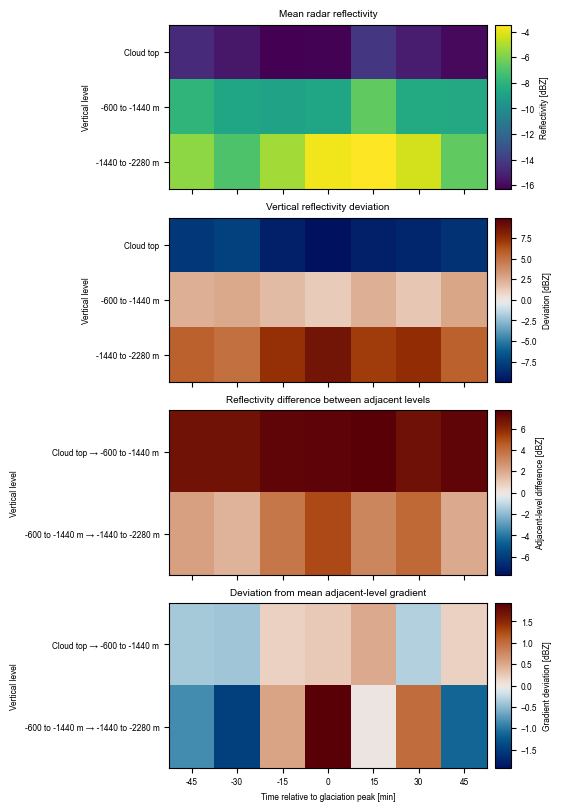

In [ ]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib import gridspec
import matplotlib.pyplot as plt
import numpy as np
from cmcrameri import cm


def symmetric_limit(data, fallback=1.0):
    """Return a finite, nonzero symmetric color limit."""
    finite_values = np.asarray(data)[np.isfinite(data)]

    if finite_values.size == 0:
        return fallback

    limit = np.max(np.abs(finite_values))

    if limit == 0:
        return fallback

    return limit


# ------------------------------------------------------------
# Calculate vertical gradients
# ------------------------------------------------------------

# Difference between consecutive vertical levels:
# gradient[i] = reflectivity[i + 1] - reflectivity[i]
vertical_gradient_map = np.diff(
    mean_map,
    axis=0,
)

gradient_level_labels = [
    f"{level_labels[i]} → {level_labels[i + 1]}"
    for i in range(len(level_labels) - 1)
]

# Mean gradient through time for each adjacent-level pair
mean_vertical_gradient = np.nanmean(
    vertical_gradient_map,
    axis=1,
    keepdims=True,
)

# Deviation from the time-mean gradient of each level pair
gradient_deviation_map = (
    vertical_gradient_map - mean_vertical_gradient
)


# ------------------------------------------------------------
# Create figure and axes
# ------------------------------------------------------------
fig_vertical = plt.figure(
    figsize=(5.501, 8.0),
    constrained_layout=True,
)

gs_vertical = gridspec.GridSpec(
    4,
    2,
    figure=fig_vertical,
    height_ratios=[1, 1, 1, 1],
    width_ratios=[1, 0.05],
)

ax_absolute = fig_vertical.add_subplot(
    gs_vertical[0, 0]
)
ax_absolute_cb = fig_vertical.add_subplot(
    gs_vertical[0, 1]
)

ax_vertical_dev = fig_vertical.add_subplot(
    gs_vertical[1, 0]
)
ax_vertical_dev_cb = fig_vertical.add_subplot(
    gs_vertical[1, 1]
)

ax_vertical_gradient = fig_vertical.add_subplot(
    gs_vertical[2, 0]
)
ax_vertical_gradient_cb = fig_vertical.add_subplot(
    gs_vertical[2, 1]
)

ax_gradient_dev = fig_vertical.add_subplot(
    gs_vertical[3, 0]
)
ax_gradient_dev_cb = fig_vertical.add_subplot(
    gs_vertical[3, 1]
)


# ------------------------------------------------------------
# Absolute reflectivity
# ------------------------------------------------------------
im_absolute = ax_absolute.imshow(
    mean_map,
    aspect="auto",
    cmap="viridis",
    origin="upper",
)

cbar_absolute = fig_vertical.colorbar(
    im_absolute,
    cax=ax_absolute_cb,
)
cbar_absolute.set_label(
    "Reflectivity [dBZ]"
)

ax_absolute.set_title(
    "Mean radar reflectivity"
)


# ------------------------------------------------------------
# Vertical reflectivity deviations
# ------------------------------------------------------------
vertical_vmax = symmetric_limit(
    dev_vs_other_levels_map
)

im_vertical_dev = ax_vertical_dev.imshow(
    dev_vs_other_levels_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(
        vmin=-vertical_vmax,
        vcenter=0,
        vmax=vertical_vmax,
    ),
    origin="upper",
)

cbar_vertical = fig_vertical.colorbar(
    im_vertical_dev,
    cax=ax_vertical_dev_cb,
)
cbar_vertical.set_label(
    "Deviation [dBZ]"
)

ax_vertical_dev.set_title(
    "Vertical reflectivity deviation"
)


# ------------------------------------------------------------
# Gradient between adjacent vertical levels
# ------------------------------------------------------------
gradient_vmax = symmetric_limit(
    vertical_gradient_map
)

im_vertical_gradient = ax_vertical_gradient.imshow(
    vertical_gradient_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(
        vmin=-gradient_vmax,
        vcenter=0,
        vmax=gradient_vmax,
    ),
    origin="upper",
)

cbar_gradient = fig_vertical.colorbar(
    im_vertical_gradient,
    cax=ax_vertical_gradient_cb,
)
cbar_gradient.set_label(
    "Adjacent-level difference [dBZ]"
)

ax_vertical_gradient.set_title(
    "Reflectivity difference between adjacent levels"
)


# ------------------------------------------------------------
# Deviations from the mean gradient at each level pair
# ------------------------------------------------------------
gradient_dev_vmax = symmetric_limit(
    gradient_deviation_map
)

im_gradient_dev = ax_gradient_dev.imshow(
    gradient_deviation_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(
        vmin=-gradient_dev_vmax,
        vcenter=0,
        vmax=gradient_dev_vmax,
    ),
    origin="upper",
)

cbar_gradient_dev = fig_vertical.colorbar(
    im_gradient_dev,
    cax=ax_gradient_dev_cb,
)
cbar_gradient_dev.set_label(
    "Gradient deviation [dBZ]"
)

ax_gradient_dev.set_title(
    "Deviation from mean adjacent-level gradient"
)


# ------------------------------------------------------------
# Common axis formatting
# ------------------------------------------------------------
all_axes = (
    ax_absolute,
    ax_vertical_dev,
    ax_vertical_gradient,
    ax_gradient_dev,
)

for ax in all_axes:
    ax.set_xticks(
        np.arange(len(rel_times_min))
    )
    ax.set_xticklabels(
        rel_times_min
    )
    ax.set_ylabel(
        "Vertical level"
    )

# The first two panels use the original vertical levels
for ax in (
    ax_absolute,
    ax_vertical_dev,
):
    ax.set_yticks(
        np.arange(len(level_labels))
    )
    ax.set_yticklabels(
        level_labels
    )

# The gradient panels use adjacent-level pairs
for ax in (
    ax_vertical_gradient,
    ax_gradient_dev,
):
    ax.set_yticks(
        np.arange(len(gradient_level_labels))
    )
    ax.set_yticklabels(
        gradient_level_labels
    )

# Display time labels only on the bottom panel
for ax in all_axes[:-1]:
    ax.tick_params(
        axis="x",
        labelbottom=False,
    )

ax_gradient_dev.set_xlabel(
    "Time relative to glaciation peak [min]"
)


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------
fig_vertical.savefig(
    "/Volumes/University_stuff/Code_Projects/MSGI/"
    "plotting/Publication_figures/"
    "Reflectivity_vertical_deviation.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
vertical_gradient_map = mean_map[1:] - mean_map[:-1]
vertical_gradient_map.mean(axis=0)

array([4.54483706, 4.21741772, 5.52798623, 6.24944637, 5.40761199,
       5.49971235, 4.69050875])

# IF plot

In [ ]:
colormap=cm.lipariS.colors
color_dd=colormap[2]
color_sev=colormap[3]
color_mod=colormap[0]


In [ ]:
# dd_data_list = []
# for year in range(2007,2009):
#     dd_data_list.append(pd.read_parquet("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/02/glaciations_with_bulk_data_V3_1_2007.parquet"))
df_glac_dd = bulk_data_colocated

In [ ]:
def get_seviri_peak_if(row):
    if_hist = row["val_pix_claas_if_hist"]
    return if_hist[row["Glac_peak_ind"]]

def get_if_glac_peak_same_cloud(row):
    if_hist = row["val_ice_frac_hist"]
    peak_value = if_hist[row["Glac_peak_ind"]]   
    if peak_value >=0:
        return peak_value
    else:
        return np.nan
    
def get_claas_if_glac_peak_same_cloud(row):
    if_hist = row["val_pix_claas_if_hist"]
    peak_value = if_hist[row["Glac_peak_ind"]]   
    
    if peak_value >=0:
        return peak_value
    else:
        return np.nan
    
def get_seviri_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        return if_hist[row["Glac_peak_ind"]-idx]
    return np.nan

def get_dd_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["val_ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        if if_hist[row["Glac_peak_ind"]-idx]>0:
            return row["cph_bulk_means"][0].mean()-1
        return np.nan
    return np.nan


def check_cph_validity(row: pd.Series):   
    ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))
    if np.isnan(int(row["val_ice_frac_hist"][ind])):
        raise TypeError("Weird error ") 
    return row["cph_bulk_means"][0].mean()-1 - row["val_ice_frac_hist"][ind]

In [ ]:
bulk_data_df_split.apply(check_cph_validity,axis=1).mean()

np.float64(0.002804261124650708)

(array([2.000e+00, 2.000e+00, 1.000e+01, 3.700e+01, 3.020e+02, 6.560e+03,
        1.659e+03, 1.530e+02, 3.900e+01, 1.000e+00]),
 array([-0.82142854, -0.67928569, -0.53714285, -0.395     , -0.25285716,
        -0.11071432,  0.03142853,  0.17357137,  0.31571422,  0.45785706,
         0.5999999 ]),
 <BarContainer object of 10 artists>)

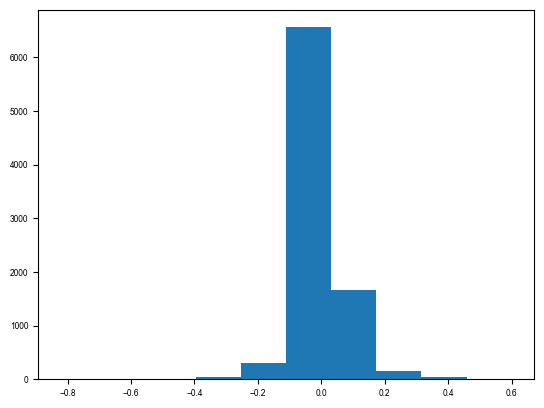

In [ ]:
plt.hist(bulk_data_df_split.apply(check_cph_validity,axis=1))

In [ ]:
np.nanmean(np.concat(bulk_data_colocated["cph_bulk_means"].to_numpy()).reshape(bulk_data_colocated.shape[0],25),axis=0)


array([1.7485601, 1.769196 , 1.8273344, 1.891936 , 1.9158106, 1.9318722,
       1.9409796, 1.9481449, 1.9526986, 1.9547105, 1.9564147, 1.9571512,
       1.9570572, 1.9573542, 1.9554582, 1.9536383, 1.9510871, 1.9467484,
       1.9421085, 1.9380995, 1.9288272, 1.9184953, 1.911126 , 1.9031578,
       1.8966271], dtype=float32)

In [ ]:
bulk_data_colocated.iloc[10]["cph_bulk_means"]

array([2.       , 2.       , 2.       , 1.9799107, 1.9799107, 1.9598215,
       1.9799107, 1.9799107, 1.9799107, 1.9799107, 2.       , 2.       ,
       2.       , 2.       , 2.       , 2.       , 2.       , 2.       ,
       2.       , 2.       , 2.       , 2.       , 2.       , 2.       ,
       2.       ], dtype=float32)

In [ ]:
for pre_peak_idx in range(-5, 5):
    # df_glac_mod[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
    #     get_seviri_pre_peak_if,
    #     axis=1,
    #     args=(pre_peak_idx,)
    # )
    df_glac_dd[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
        get_seviri_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    df_glac_dd[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
        get_dd_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    # df_glac_mod[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
    #         get_dd_pre_peak_if,
    #         axis=1,
    #         args=(pre_peak_idx,)
    #     )
    

In [ ]:
df_glac_dd["val_1_prepeak_if"].dropna()

91      0.625627
160     0.964286
275     0.955523
324     0.907924
386     0.568300
          ...   
8905    0.830870
8977    0.512565
9046    0.926226
9081    0.613636
9087    0.975399
Name: val_1_prepeak_if, Length: 112, dtype: float64

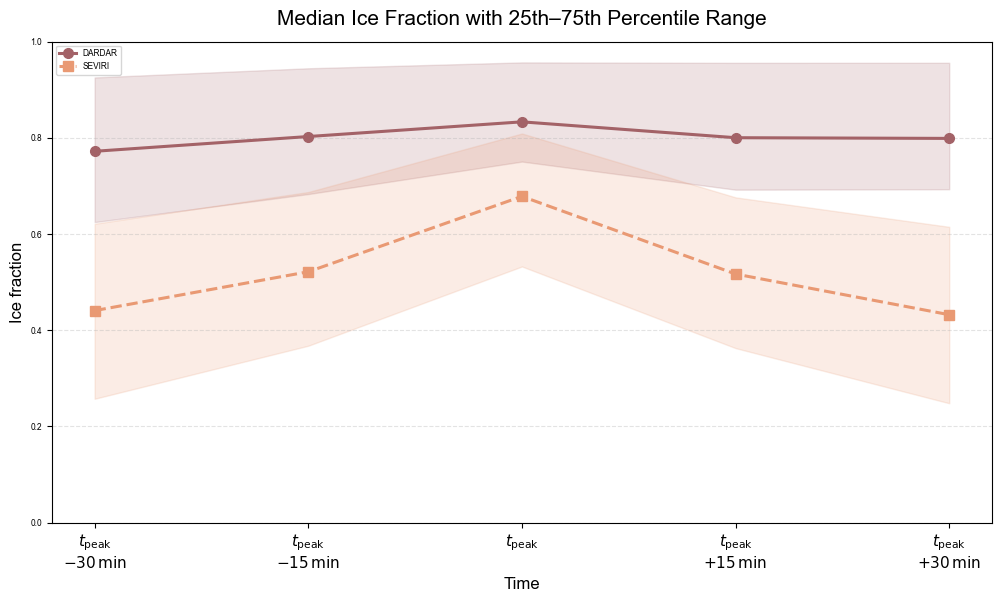

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# timesteps in plotting order


# corresponding column names
dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
# modis_cols  = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

# x_labels = [
#     # r"$t_{\mathrm{peak}}-45\mathrm{min}$",
#     r"$t_{\mathrm{peak}}-30\mathrm{min}$",
#     r"$t_{\mathrm{peak}}-15\mathrm{min}$",
#     r"$t_{\mathrm{peak}}$",
#     r"$t_{\mathrm{peak}}+15\mathrm{min}$",
#     r"$t_{\mathrm{peak}}+30\mathrm{min}$",
#     # r"$t_{\mathrm{peak}}+45\mathrm{min}$",
# ]

x_labels = [
    "$t_{\\mathrm{peak}}$\n$-30\\,\\mathrm{min}$",
    "$t_{\\mathrm{peak}}$\n$-15\\,\\mathrm{min}$",
    "$t_{\\mathrm{peak}}$",
    "$t_{\\mathrm{peak}}$\n$+15\\,\\mathrm{min}$",
    "$t_{\\mathrm{peak}}$\n$+30\\,\\mathrm{min}$",
]


def clean_vals(series):
    vals = series.dropna()
    vals = vals[(vals >= 0) & (vals <= 1)]
    return vals.values

def median_q25_q75(vals):
    if len(vals) == 0:
        return np.nan, np.nan, np.nan
    q25 = np.percentile(vals, 25)
    med = np.percentile(vals, 50)
    med = np.nanmean(vals)
    q75 = np.percentile(vals, 75)
    return q25, med, q75

# store percentile stats
dardar_q25, dardar_med, dardar_q75 = [], [], []
seviri_q25, seviri_med, seviri_q75 = [], [], []
# modis_q25, modis_med, modis_q75 = [], [], []

for dd_col, sev_col in zip(dardar_cols, seviri_cols):
    # DARDAR
    dd_vals = clean_vals(df_glac_dd[dd_col])
    q25, med, q75 = median_q25_q75(dd_vals)
    dardar_q25.append(q25)
    dardar_med.append(med)
    dardar_q75.append(q75)

    # SEVIRI
    sev_vals = clean_vals(df_glac_dd[sev_col])
    q25, med, q75 = median_q25_q75(sev_vals)
    seviri_q25.append(q25)
    seviri_med.append(med)
    seviri_q75.append(q75)

    # MODIS
    # mod_vals = clean_vals(df_glac_mod[mod_col])
    # q25, med, q75 = median_q25_q75(mod_vals)
    # modis_q25.append(q25)
    # modis_med.append(med)
    # modis_q75.append(q75)

# convert to arrays
dardar_q25 = np.array(dardar_q25)
dardar_med = np.array(dardar_med)
dardar_q75 = np.array(dardar_q75)

seviri_q25 = np.array(seviri_q25)
seviri_med = np.array(seviri_med)
seviri_q75 = np.array(seviri_q75)

# modis_q25 = np.array(modis_q25)
# modis_med = np.array(modis_med)
# modis_q75 = np.array(modis_q75)

x = np.arange(len(x_labels))

plt.figure(figsize=(10, 6))

# median lines
line1, = plt.plot(
    x, dardar_med,
    marker="o", linestyle="-", linewidth=2.2, markersize=7,
    label="DARDAR", color = color_dd
)

line2, = plt.plot(
    x, seviri_med,
    marker="s", linestyle="--", linewidth=2.2, markersize=7,
    label="SEVIRI", color = color_sev
)

# line3, = plt.plot(
#     x, modis_med,
#     marker="^", linestyle=":", linewidth=2.2, markersize=7,
#     label="MODIS", color = color_mod
# )

# shaded percentile bands
plt.fill_between(
    x, dardar_q25, dardar_q75,
    color=line1.get_color(), alpha=0.18
)

plt.fill_between(
    x, seviri_q25, seviri_q75,
    color=line2.get_color(), alpha=0.18
)

# plt.fill_between(
#     x, modis_q25, modis_q75,
#     color=line3.get_color(), alpha=0.18
# )

plt.xticks(x, x_labels, fontsize=11)
plt.ylabel("Ice fraction", fontsize=12)
plt.xlabel("Time", fontsize=12)
plt.title("Median Ice Fraction with 25th–75th Percentile Range", fontsize=15, pad=12)

plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
# plt.ylim(0.8)
plt.show()

In [ ]:
eps=1e-4
for col in dardar_cols:
    raw = pd.to_numeric(df_glac_dd[col], errors="coerce").dropna()

    first = raw[raw.between(0, 1)]
    second = raw[raw.between(-eps, 1 + eps)]

    print(
        col,
        "above 1:", (raw > 1).sum(),
        "first n:", len(first),
        "first fraction:", (first >= 0.80).mean(),
        "second n:", len(second),
        "second fraction:", (second > 0.85).mean(),
    )

val_2_prepeak_if above 1: 0 first n: 129 first fraction: 0.5658914728682171 second n: 129 second fraction: 0.46511627906976744
val_1_prepeak_if above 1: 0 first n: 112 first fraction: 0.6071428571428571 second n: 112 second fraction: 0.5357142857142857
val_0_prepeak_if above 1: 0 first n: 108 first fraction: 0.7037037037037037 second n: 108 second fraction: 0.6296296296296297
val_-1_prepeak_if above 1: 0 first n: 77 first fraction: 0.5844155844155844 second n: 77 second fraction: 0.5454545454545454
val_-2_prepeak_if above 1: 0 first n: 76 first fraction: 0.6578947368421053 second n: 76 second fraction: 0.5921052631578947
